In [29]:
import pandas as pd
import matplotlib.pyplot as plt

In [30]:
df = pd.read_excel('data-bakery.xlsx')

In [31]:
df.columns = df.columns.str.lower()
df.head()

,transaction_id,date,time,customer_id,customer_age,customer_gender,product,category,quantity,unit_price,...,promotion_applied,promotion_type,promotion_score,customer_rating,customer_segment,loyalty_member,profit,waste_cost,recommended_product,recommended_discount
0,TXN000038,2023-01-01,07:13:00,CUST01289,32,Male,Rusk,Biscuits & Cookies,1,34.79,...,Yes,Festival,100,4,Young Professional,Yes,-4.28,7.71,Rusk,13.0
1,TXN000039,2023-01-01,07:13:00,CUST01289,32,Male,Peanut Butter,Spreads,4,176.62,...,Yes,Festival,100,4,Young Professional,Yes,-105.15,171.43,Bread,9.0
2,TXN000040,2023-01-01,07:13:00,CUST01289,32,Male,Black Forest Cake,Cakes,2,448.03,...,Yes,Festival,100,4,Young Professional,Yes,-461.14,520.00,Soft Drink,14.7
3,TXN000041,2023-01-01,07:13:00,CUST01289,32,Male,Honey,Spreads,4,219.12,...,Yes,Festival,100,4,Young Professional,Yes,-92.52,222.86,Honey,3.3
4,TXN000043,2023-01-01,08:15:00,CUST01077,17,Female,Tea,Beverages,2,29.85,...,Yes,Festival,100,4,Student,No,-0.66,24.00,Biscuit,25.2


In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16569 entries, 0 to 16568
Data columns (total 41 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   transaction_id        16569 non-null  str           
 1   date                  16569 non-null  datetime64[us]
 2   time                  16569 non-null  object        
 3   customer_id           16569 non-null  str           
 4   customer_age          16569 non-null  int64         
 5   customer_gender       16569 non-null  str           
 6   product               16569 non-null  str           
 7   category              16569 non-null  str           
 8   quantity              16569 non-null  int64         
 9   unit_price            16569 non-null  float64       
 10  discount_percentage   16569 non-null  float64       
 11  discount_amount       16569 non-null  float64       
 12  selling_price         16569 non-null  float64       
 13  total_bill            16569

In [34]:
x = df['date']
y = df['total_bill']

### Total Bill by Month in 2023

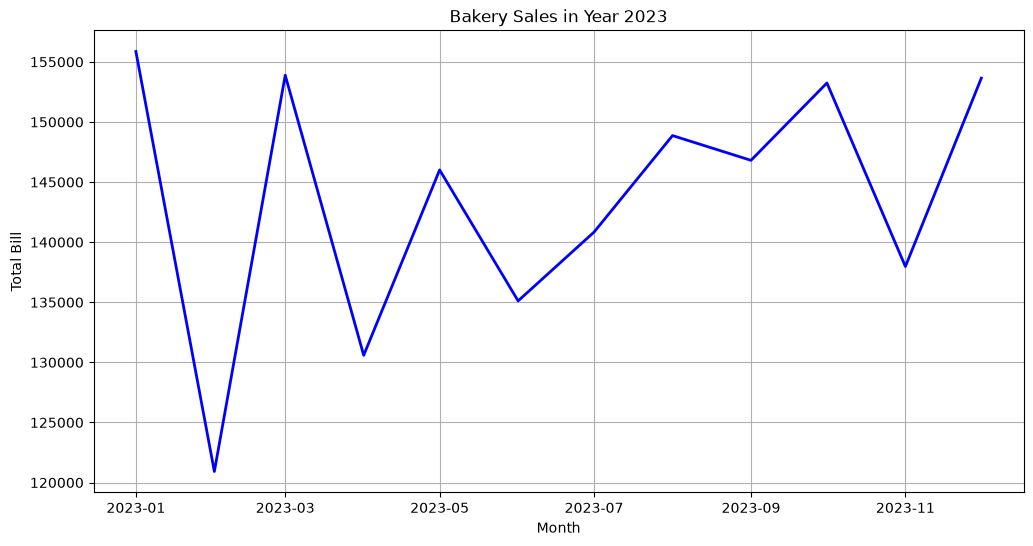

In [35]:
df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y')

df_2023 = df[df['date'].dt.year == 2023]

plt.figure(figsize=(12, 6))
monthly = df_2023.groupby(df_2023['date'].dt.to_period('M'))['total_bill'].sum()
monthly.index = monthly.index.to_timestamp()

plt.plot(monthly.index, monthly.values, color='blue', linewidth=2)
plt.title("Bakery Sales in Year 2023")
plt.xlabel("Month")
plt.ylabel("Total Bill")
plt.grid(True)
plt.show()

### Total Bills by Each Category

In [ ]:
print(df["category"].unique())

<StringArray>
['Biscuits & Cookies',            'Spreads',              'Cakes',
          'Beverages',     'Bakery Staples',              'Dairy',
           'Cupcakes',     'Savoury Snacks',            'Muffins',
      'Bakery Snacks']
Length: 10, dtype: str


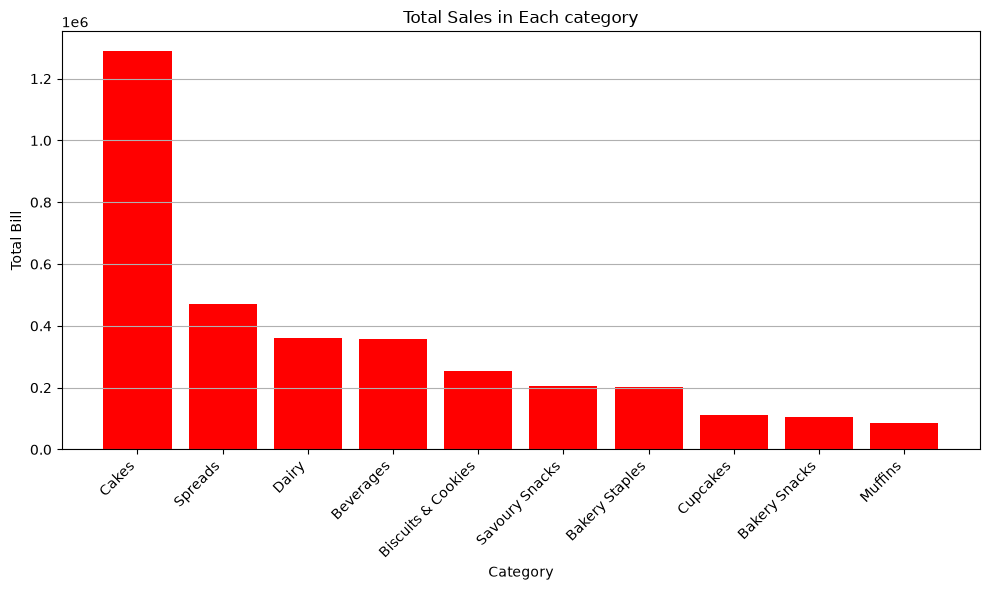

In [36]:
y = df.groupby('category')['total_bill'].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
plt.bar(y.index, y.values, color='red')
plt.title("Total Sales in Each category")
plt.xlabel("Category")
plt.ylabel("Total Bill")
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

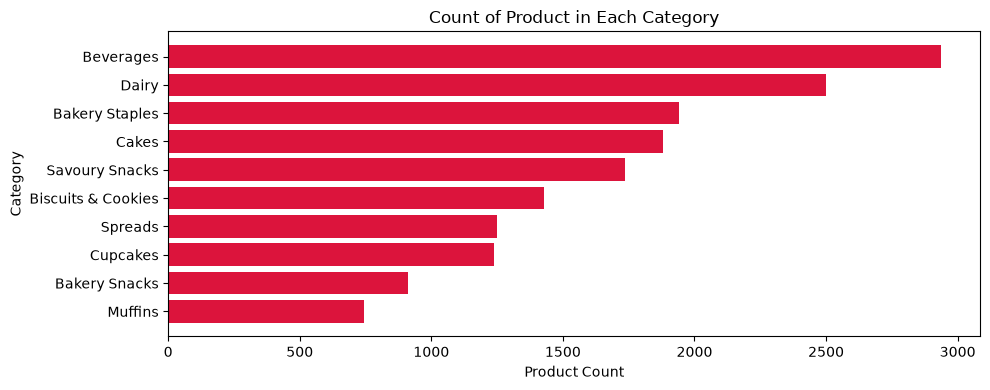

In [37]:
count_prod_in_cat = df.groupby('category')['product'].count().sort_values(ascending=True)

plt.figure(figsize=(10, 4))
plt.barh(count_prod_in_cat.index, count_prod_in_cat.values, color='crimson')
plt.title('Count of Product in Each Category')
plt.ylabel('Category')
plt.xlabel('Product Count')
plt.tight_layout()
plt.show()

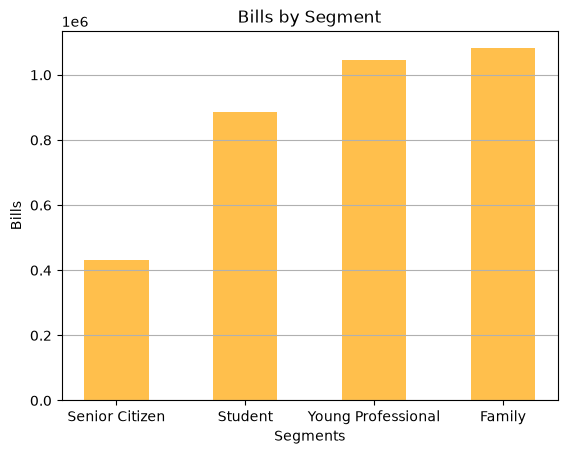

In [38]:
bills_by_segment = df.groupby('customer_segment')['total_bill'].sum().sort_values(ascending=True)
plt.bar(bills_by_segment.index, bills_by_segment.values, color = 'orange', alpha=0.7, width=0.5)
plt.title('Bills by Segment')
plt.xlabel('Segments')
plt.ylabel('Bills')
plt.grid(axis='y')
plt.show()